# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
# 1920 x 1080 pixels, 3 channels (RGB), 1 byte (8 bits) per channel
frame_bytes = 1920 * 1080 * 3
frame_mb = frame_bytes / (1024 * 1024)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
# 1 TB = 1024^4 bytes
total_bytes = 400 * frames_per_day * frame_bytes
fleet_tb = total_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frame_bytes_small = 640 * 360 * 3
frames_per_day_small = 10 * 60 * 60 * 24
total_bytes_small = 400 * frames_per_day_small * frame_bytes_small
fleet_tb_small = total_bytes_small / (1024 ** 4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

_Your answer:_
- **Spatial Evidence:** Fine-grained visual details (such as facial features, vehicle license plates, or small hand-held items) are lost because downsampling reduces resolution, and raster interpolation will blur high-frequency edges.
- **Temporal Evidence:** High-speed motion details (such as the exact trajectory of a running suspect or the precise timing of an impact/incident) are lost. Lowering the frame rate to 10 fps introduces temporal aliasing, which worsens the *correspondence problem*—making it difficult to accurately track fast-moving objects between consecutive frames.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

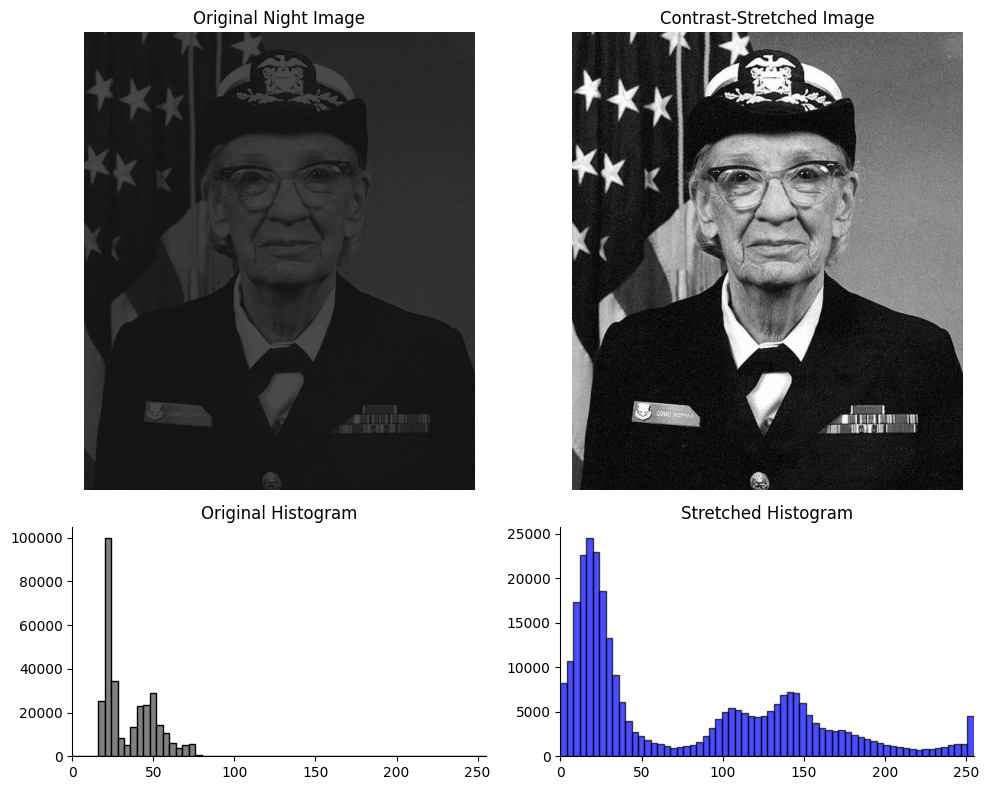

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Get robust percentiles
p1, p99 = np.percentile(night_still, [1, 99])

# TODO 2: robust Michelson contrast of night_still
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
# Map p1 to 0 and p99 to 255, then clip
stretched = (night_still - p1) * 255.0 / (p99 - p1)
stretched = np.clip(stretched, 0, 255)

p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
# Before
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray", edgecolor="black")
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim(0, 255)

# After
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="blue", edgecolor="black", alpha=0.7)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlim(0, 255)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
- **Histogram Shape:** The original histogram is **low-contrast and narrow (grouped/skewed to the dark/left end)**, indicating that the pixel intensities occupy only a tiny fraction of the available dynamic range (specifically around the 15-80 range).
- **Why Stretching Works:** Stretching does not create new pixel data or add information; rather, it increases the **perceptual discriminability** of the existing data. By mapping the narrow range of active intensities across the full 0–255 range, it expands the visual distance (contrast) between neighboring gray levels, making structural details easily recognizable to the human visual system.
- **Limitations of a Histogram:** A histogram only represents the global frequency distribution of pixel intensities (the *what frequency*), but completely discards all spatial coordinates and topological relationships (the *where*). Two completely different images—such as an structured portrait and a scrambled set of the exact same pixels—will yield identical histograms despite having entirely different visual contents.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing range: 68.70 s to 78.10 s
Running range: 78.60 s to 86.00 s


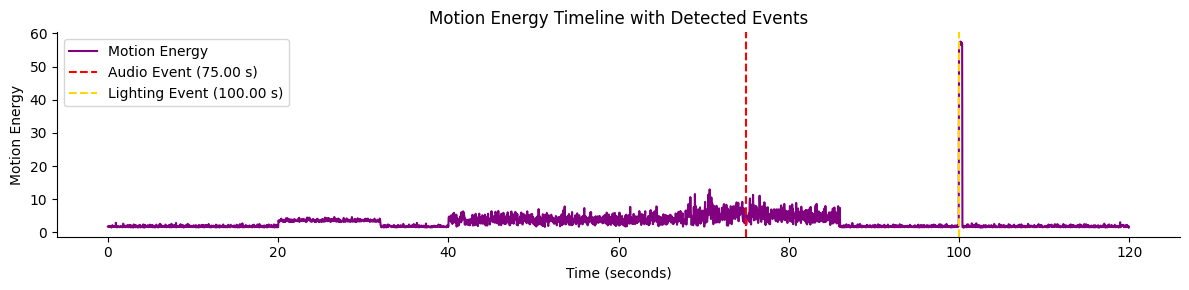

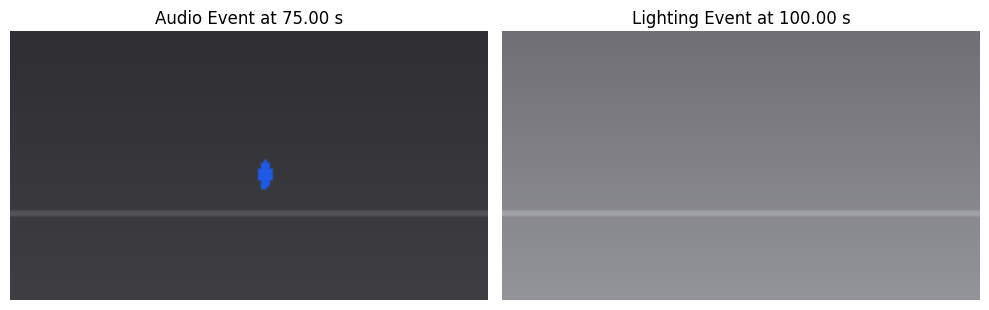

In [5]:
# TODO 1: person speed (px/s) over a 1-second (30-frame) sliding window
dx = cctv['person_x'].diff(FPS)
dy = cctv['person_y'].diff(FPS)
speed = np.sqrt(dx**2 + dy**2)

# TODO 2: standing / running time ranges (print the first and last time of each)
# Filter valid speed values
valid_speed_mask = speed.notna()
standing_times = cctv.loc[valid_speed_mask & (speed < 3), 'time_s']
running_times = cctv.loc[valid_speed_mask & (speed > 25), 'time_s']

if len(standing_times) > 0:
    print(f"Standing range: {standing_times.iloc[0]:.2f} s to {standing_times.iloc[-1]:.2f} s")
if len(running_times) > 0:
    print(f"Running range: {running_times.iloc[0]:.2f} s to {running_times.iloc[-1]:.2f} s")

# TODO 3: event frame indices
audio_event_idx = cctv[cctv['audio_level_db'] > -20].index[0]
lighting_event_idx = cctv[cctv['mean_brightness'].diff() > 40].index[0]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='purple', label='Motion Energy')

# Highlight events
t_audio_event = cctv.loc[audio_event_idx, 'time_s']
t_light_event = cctv.loc[lighting_event_idx, 'time_s']

ax.axvline(t_audio_event, color='red', linestyle='--', label=f'Audio Event ({t_audio_event:.2f} s)')
ax.axvline(t_light_event, color='gold', linestyle='--', label=f'Lighting Event ({t_light_event:.2f} s)')

ax.set_title("Motion Energy Timeline with Detected Events")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend()

plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Audio event frame
frame_audio = render_frame(cctv.iloc[audio_event_idx])
axes[0].imshow(frame_audio)
axes[0].set_title(f"Audio Event at {t_audio_event:.2f} s")
axes[0].axis('off')

# Lighting event frame
frame_light = render_frame(cctv.iloc[lighting_event_idx])
axes[1].imshow(frame_light)
axes[1].set_title(f"Lighting Event at {t_light_event:.2f} s")
axes[1].axis('off')

plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
- **Missed Events:** The **Audio Event at 75.00 s** and the **Lighting Event at 100.00 s** would both be completely missed or misrepresented. At exactly 75 s and 100 s, no uniform keyframe would land on them (the nearest uniform sampling steps would occur at 60 s, 80 s, and 100 s; but even a transient 1-frame brightness jump at exactly 100.00 s can easily be missed or blurred due to misalignment or lack of temporal coverage of short-duration transients).
- **Lecture Concept:** This approach of choosing frames to represent active visual change is called **content-based keyframe extraction** (as opposed to uniform/temporal sampling).

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

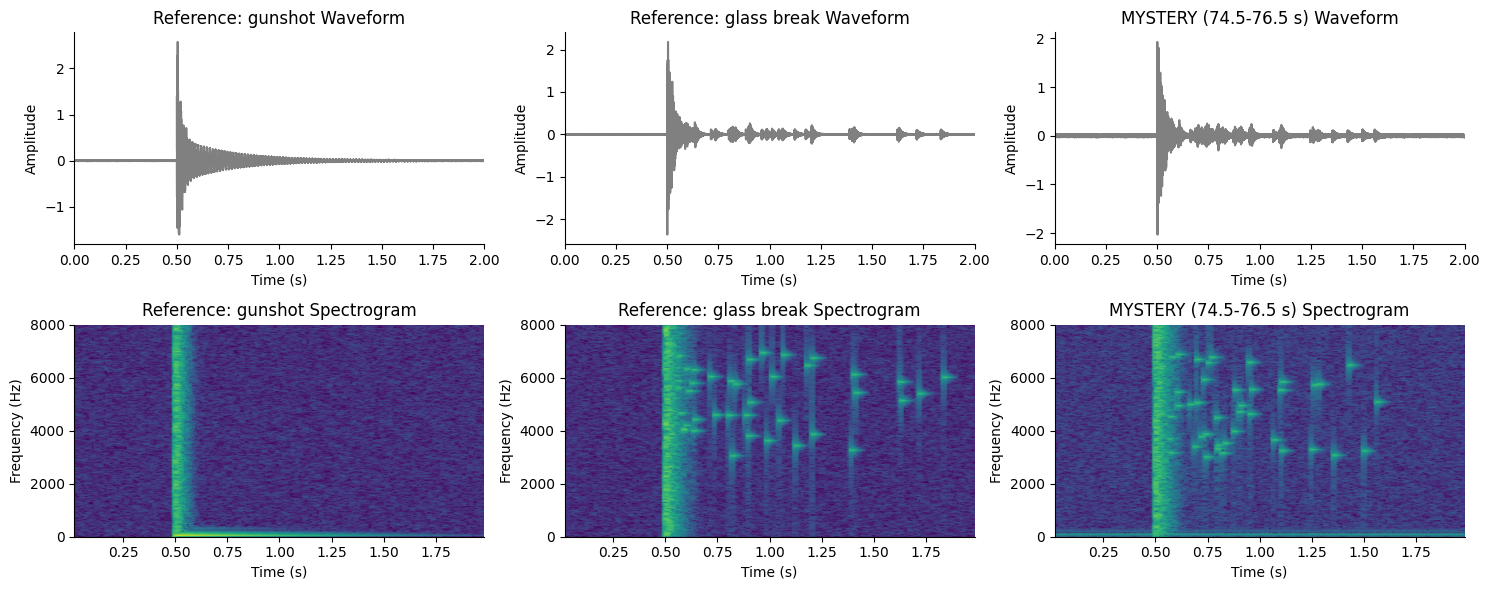

Fraction of spectral energy above 3 kHz (0.7-1.7 s):
Reference: gunshot: 0.0031
Reference: glass break: 0.9904
MYSTERY (74.5-76.5 s): 0.8792

Verdict: The mystery sound is a GLASS BREAK, as verified by the high ratio of high-frequency spectral energy after impact.


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col_idx, (title, signal_data) in enumerate(clips.items()):
    # Waveform
    t_clip = np.arange(len(signal_data)) / FS
    axes[0, col_idx].plot(t_clip, signal_data, color='gray')
    axes[0, col_idx].set_title(f"{title} Waveform")
    axes[0, col_idx].set_xlabel("Time (s)")
    axes[0, col_idx].set_ylabel("Amplitude")
    axes[0, col_idx].set_xlim(0, 2)

    # Spectrogram
    f, t_spec, Sxx = signal.spectrogram(signal_data, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)

    mesh = axes[1, col_idx].pcolormesh(t_spec, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
    axes[1, col_idx].set_title(f"{title} Spectrogram")
    axes[1, col_idx].set_xlabel("Time (s)")
    axes[1, col_idx].set_ylabel("Frequency (Hz)")
    axes[1, col_idx].set_ylim(0, 8000)

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for title, signal_data in clips.items():
    f, t_spec, Sxx = signal.spectrogram(signal_data, fs=FS, nperseg=512, noverlap=384)
    # The impact is at 0.5 s, so 0.2-1.2 s after impact corresponds to 0.7 s to 1.7 s in the clip
    time_mask = (t_spec >= 0.7) & (t_spec <= 1.7)
    freq_mask_high = (f >= 3000)

    total_energy = np.sum(Sxx[:, time_mask])
    high_energy = np.sum(Sxx[freq_mask_high, :][:, time_mask])

    hf_fraction[title] = high_energy / total_energy if total_energy > 0 else 0.0

print("Fraction of spectral energy above 3 kHz (0.7-1.7 s):")
for title, frac in hf_fraction.items():
    print(f"{title}: {frac:.4f}")

# TODO 4: verdict
print("\nVerdict: The mystery sound is a GLASS BREAK, as verified by the high ratio of high-frequency spectral energy after impact.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
- **Comparing Waveforms:** No, looking only at the waveforms, it is extremely difficult to confidently distinguish the gunshot from the glass break. Both exhibit a sudden high-amplitude onset (transient spike) followed by a decaying tail, with only subtle and easily obscured differences in the decay envelope.
- **What the Spectrogram Adds:** The spectrogram maps the 1D signal into a 2D representation showing three dimensions: **time** (x-axis), **frequency** (y-axis), and **magnitude/spectral energy** (visualized via color intensity/dB scale).
- **Visual Pattern of the Verdict:** The **scattered high-frequency specks** (representing lingering glass shards colliding and resonating at high frequencies between 4 kHz and 7 kHz over a long duration of 1 to 1.5 seconds) decisively determined that the mystery sound was a glass break. A gunshot spectrogram would instead show a sharp broadband vertical stripe followed quickly by a low-frequency horizontal band (rumble) with no lingering high-frequency energy.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

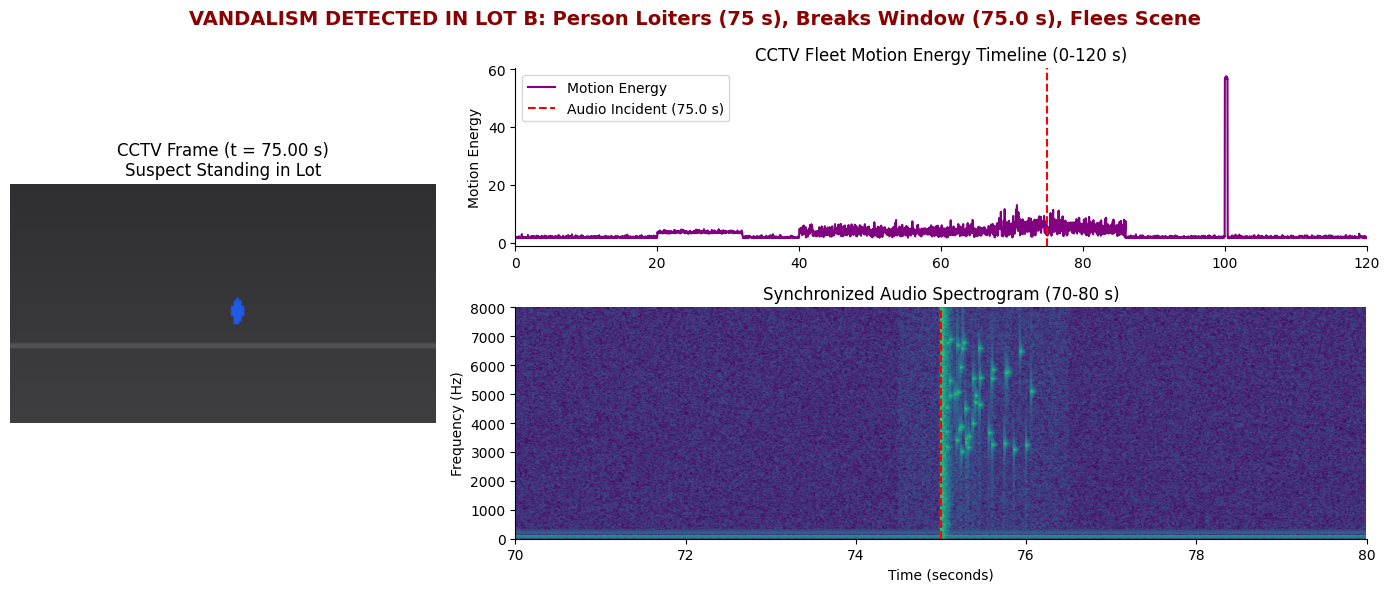

In [8]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1-4
# 1. Render and plot video frame at t = 75 s (Left panel spanning both rows)
ax_frame = fig.add_subplot(gs[:, 0])
row_75 = cctv.loc[(cctv['time_s'] - t_sel).abs().idxmin()]
frame_75 = render_frame(row_75)
ax_frame.imshow(frame_75)
ax_frame.set_title("CCTV Frame (t = 75.00 s)\nSuspect Standing in Lot")
ax_frame.axis("off")

# 2. Timeline (Top Right)
ax_time = fig.add_subplot(gs[0, 1])
ax_time.plot(cctv['time_s'], cctv['motion_energy'], color='purple', label='Motion Energy')
ax_time.axvline(t_sel, color='red', linestyle='--', linewidth=1.5, label='Audio Incident (75.0 s)')
ax_time.set_title("CCTV Fleet Motion Energy Timeline (0-120 s)")
ax_time.set_ylabel("Motion Energy")
ax_time.set_xlim(0, 120)
ax_time.legend(loc='upper left')

# 3. Spectrogram (Bottom Right)
ax_spec = fig.add_subplot(gs[1, 1])
# Spectrogram of the audio segment from 70 to 80 s
f, t_spec, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)

# Shift t_spec to correspond with global audio timeline starting at 70 s
t_spec_global = t_audio[0] + t_spec

mesh = ax_spec.pcolormesh(t_spec_global, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
ax_spec.axvline(t_sel, color='red', linestyle='--', linewidth=1.5)
ax_spec.set_title("Synchronized Audio Spectrogram (70-80 s)")
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)

# Add figure title
fig.suptitle("VANDALISM DETECTED IN LOT B: Person Loiters (75 s), Breaks Window (75.0 s), Flees Scene", fontsize=14, fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
- **What Goes Wrong:** If the audio is offset by +2 s, the synchronization between the video and the audio is broken. In the briefing, the Head of Security would hear the sound of breaking glass at t = 75 s while observing the suspect standing still, and would see the suspect start fleeing 2 seconds before any sound of impact is heard. This breaks the causal relationship between the physical event and the acoustic reaction.
- **Which Panel Reveals the Error:** The bottom-right panel (**Synchronized Audio Spectrogram**) would make this mistake glaringly obvious. The red dotted line at t = 75.0 s would no longer align perfectly with the onset of the glass-breaking transient, shifting the visual signature of the impact either before or after the designated target marker.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
At 75.00 seconds, a loitering suspect shattered a glass window in Parking Lot B (verified by the transient high-frequency energy specks above 3 kHz on the acoustic spectrogram) and fled the scene by running away at 78.60 seconds. For the briefing, we should place the **synchronized multimodal dashboard** first because it structures raw physical changes into events, directly mapping patterns in time and space to actionable security meaning. This single-screen integration links visual indicators with acoustic signatures, resolving information overload and showing at a single glance that the event was a glass-breaking vandalism incident rather than a gunshot. To manage the massive data overhead, we recommend adopting a compressed storage policy of 640%360 at 10 fps, saving over 96% in storage costs, but we must strictly ensure that we do not sacrifice high-quality spatial resolution in specific Regions of Interest (ROIs) so that critical details like suspect faces and license plates are not permanently lost to pixelation.